In [1]:
from pathlib import Path

import pandas as pd
import numpy as np

PROJECT_ROOT = Path.cwd()

# If running from the notebooks directory, move to the project root.
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "fake_job_postings.csv"

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())

Project root: /home/deepak/Documents/JobShield-AI
Dataset path: /home/deepak/Documents/JobShield-AI/data/raw/fake_job_postings.csv
Dataset exists: True


In [2]:
df = pd.read_csv(DATA_PATH)

print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

Dataset dimensions: (17880, 18)

Column names:
['job_id', 'title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent']

First five rows:


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   job_id               17880 non-null  int64
 1   title                17880 non-null  str  
 2   location             17534 non-null  str  
 3   department           6333 non-null   str  
 4   salary_range         2868 non-null   str  
 5   company_profile      14572 non-null  str  
 6   description          17879 non-null  str  
 7   requirements         15184 non-null  str  
 8   benefits             10668 non-null  str  
 9   telecommuting        17880 non-null  int64
 10  has_company_logo     17880 non-null  int64
 11  has_questions        17880 non-null  int64
 12  employment_type      14409 non-null  str  
 13  required_experience  10830 non-null  str  
 14  required_education   9775 non-null   str  
 15  industry             12977 non-null  str  
 16  function             11425 non-nu

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    "../data/raw/fake_job_postings.csv"
)

print(df["fraudulent"].value_counts())

print("\nClass distribution (%):")
print(
    df["fraudulent"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

fraudulent
0    17014
1      866
Name: count, dtype: int64

Class distribution (%):
fraudulent
0    95.16
1     4.84
Name: proportion, dtype: float64


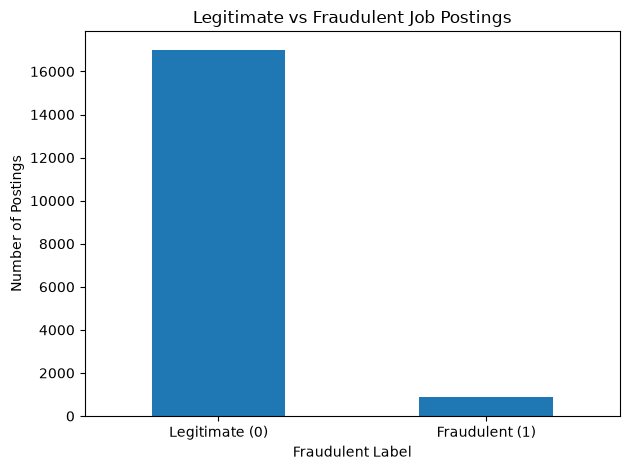

In [5]:
df["fraudulent"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Legitimate vs Fraudulent Job Postings")
plt.xlabel("Fraudulent Label")
plt.ylabel("Number of Postings")
plt.xticks([0, 1], ["Legitimate (0)", "Fraudulent (1)"], rotation=0)
plt.tight_layout()
plt.show()

In [6]:
import pandas as pd

missing_report = pd.DataFrame({
    "Column": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Missing_Count": df.isnull().sum().values,
    "Missing_Percentage": (
        df.isnull().mean().values * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_report)

,Column,Data_Type,Missing_Count,Missing_Percentage
4,salary_range,str,15012,83.96
3,department,str,11547,64.58
14,required_education,str,8105,45.33
8,benefits,str,7212,40.34
13,required_experience,str,7050,39.43
16,function,str,6455,36.10
15,industry,str,4903,27.42
12,employment_type,str,3471,19.41
5,company_profile,str,3308,18.50
7,requirements,str,2696,15.08


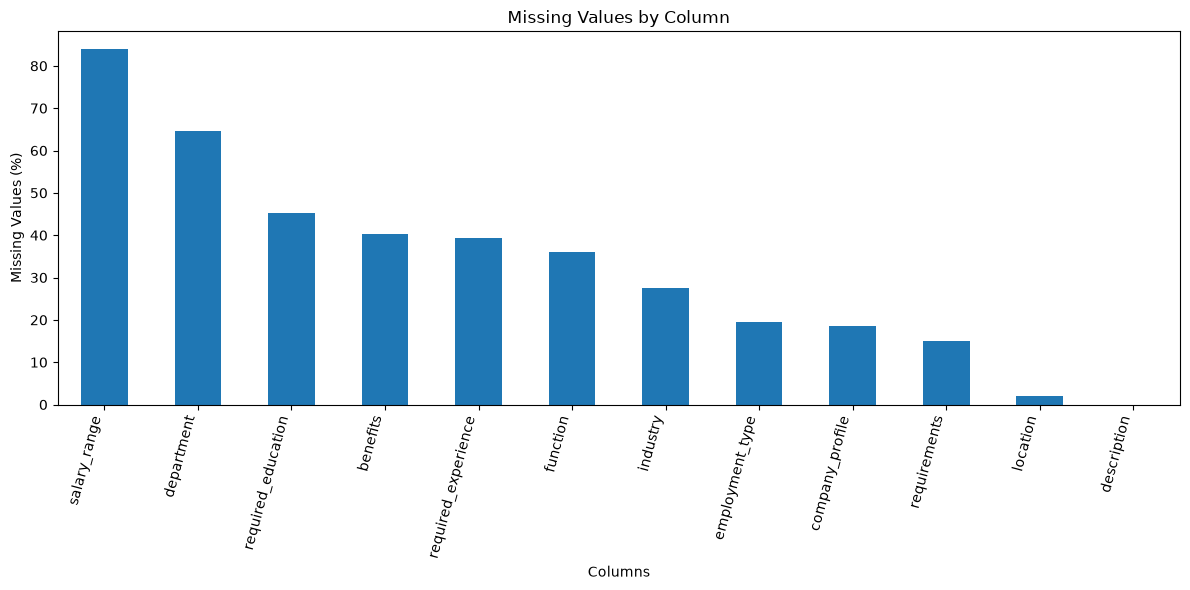

In [7]:
import matplotlib.pyplot as plt

missing_percent = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

missing_percent = missing_percent[
    missing_percent > 0
]

plt.figure(figsize=(12, 6))

missing_percent.plot(kind="bar")

plt.title("Missing Values by Column")
plt.xlabel("Columns")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()

plt.show()

In [8]:
column = "company_profile"

if column in df.columns:
    missing_indicator = df[column].isnull()

    print("Fraud rate when company profile is missing:")
    print(
        df.loc[
            missing_indicator, "fraudulent"
        ].mean()
    )

    print("\nFraud rate when company profile is present:")
    print(
        df.loc[
            ~missing_indicator, "fraudulent"
        ].mean()
    )

Fraud rate when company profile is missing:
0.17744860943168078

Fraud rate when company profile is present:
0.01914630798792204


In [9]:
print("Exact duplicate rows:", df.duplicated().sum())

Exact duplicate rows: 0


In [10]:
print(df.columns.tolist())

['job_id', 'title', 'location', 'department', 'salary_range', 'company_profile', 'description', 'requirements', 'benefits', 'telecommuting', 'has_company_logo', 'has_questions', 'employment_type', 'required_experience', 'required_education', 'industry', 'function', 'fraudulent']


In [11]:
quality_report = {
    "row_count": len(df),
    "column_count": len(df.columns),
    "exact_duplicates": int(df.duplicated().sum()),
    "missing_target": int(df["fraudulent"].isna().sum()),
    "fraudulent_count": int(
        (df["fraudulent"] == 1).sum()
    ),
    "legitimate_count": int(
        (df["fraudulent"] == 0).sum()
    )
}

display(pd.Series(quality_report, name="Value"))

row_count           17880
column_count           18
exact_duplicates        0
missing_target          0
fraudulent_count      866
legitimate_count    17014
Name: Value, dtype: int64

In [12]:
print(df["fraudulent"].value_counts(dropna=False))

fraudulent
0    17014
1      866
Name: count, dtype: int64
